In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
train_data = pd.read_csv("churn-bigml-80.csv")
test_data = pd.read_csv("churn-bigml-20.csv")

In [4]:
train_data.shape, test_data.shape

((2666, 20), (667, 20))

In [5]:
train_data.head(), test_data.head()

(  State  Account length  ...  Customer service calls  Churn
 0    KS             128  ...                       1  False
 1    OH             107  ...                       1  False
 2    NJ             137  ...                       0  False
 3    OH              84  ...                       2  False
 4    OK              75  ...                       3  False
 
 [5 rows x 20 columns],
   State  Account length  ...  Customer service calls  Churn
 0    LA             117  ...                       1  False
 1    IN              65  ...                       4   True
 2    NY             161  ...                       4   True
 3    SC             111  ...                       2  False
 4    HI              49  ...                       1  False
 
 [5 rows x 20 columns])

In [7]:
y = train_data.pop("Churn")
X = train_data



In [11]:
train_data.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3


In [16]:
y.unique()

array([False,  True])

In [17]:
y = y.astype(int)

In [18]:
y.unique()

array([0, 1])

In [19]:
for col in X.select_dtypes(exclude="number"):
  print(col, X[col].nunique())

State 51
International plan 2
Voice mail plan 2


In [20]:
X = pd.get_dummies(X, dtype=int, drop_first=True)

In [21]:
X.head()

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,State_AL,State_AR,State_AZ,State_CA,State_CO,State_CT,State_DC,State_DE,State_FL,State_GA,State_HI,State_IA,State_ID,State_IL,State_IN,State_KS,State_KY,State_LA,State_MA,State_MD,State_ME,State_MI,State_MN,State_MO,State_MS,State_MT,State_NC,State_ND,State_NE,State_NH,State_NJ,State_NM,State_NV,State_NY,State_OH,State_OK,State_OR,State_PA,State_RI,State_SC,State_SD,State_TN,State_TX,State_UT,State_VA,State_VT,State_WA,State_WI,State_WV,State_WY,International plan_Yes,Voice mail plan_Yes
0,128,415,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,107,415,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,137,415,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,84,408,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
4,75,415,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


In [23]:
X_train, X_test, y_train, y_test = train_test_split(X,y)

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [24]:
model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression())])

In [25]:
coeffs = model.named_steps["logisticregression"]

In [34]:
coefs = pd.Series(coeffs.coef_[0], index=X.columns).sort_values()

In [35]:
coefs

,0
Voice mail plan_Yes,-0.877709
Total intl calls,-0.271083
State_VA,-0.188818
State_AL,-0.130035
State_IN,-0.123139
...,...
Total day charge,0.388858
Total day minutes,0.388947
Number vmail messages,0.484176
International plan_Yes,0.731084


In [36]:
import numpy as np

In [38]:
pd.DataFrame({
    "odds_ratio": np.exp(coeffs.coef_[0]),
    "Coefficients": coeffs.coef_[0]
}, index=X.columns).sort_values("Coefficients")


,odds_ratio,Coefficients
Voice mail plan_Yes,0.415734,-0.877709
Total intl calls,0.762553,-0.271083
State_VA,0.827937,-0.188818
State_AL,0.878065,-0.130035
State_IN,0.884140,-0.123139
...,...,...
Total day charge,1.475296,0.388858
Total day minutes,1.475427,0.388947
Number vmail messages,1.622836,0.484176
International plan_Yes,2.077331,0.731084


In [39]:
y_pred = model.predict(X_test)

In [42]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, confusion_matrix

print("Accuracy: ", accuracy_score(y_pred=y_pred, y_true=y_test))
print("Confusion matrix: ", confusion_matrix(y_pred=y_pred, y_true=y_test))
print("Precision score: ", precision_score(y_pred=y_pred, y_true=y_test, average="macro"))
print("Recall score: ", recall_score(y_pred=y_pred, y_true=y_test, average="macro"))

Accuracy:  0.8680659670164917
Confusion matrix:  [[550  19]
 [ 69  29]]
Precision score:  0.7463482767905223
Recall score:  0.6312632258527313


In [44]:
fpr, tpr, thresholds = roc_curve(y_pred, y_test)

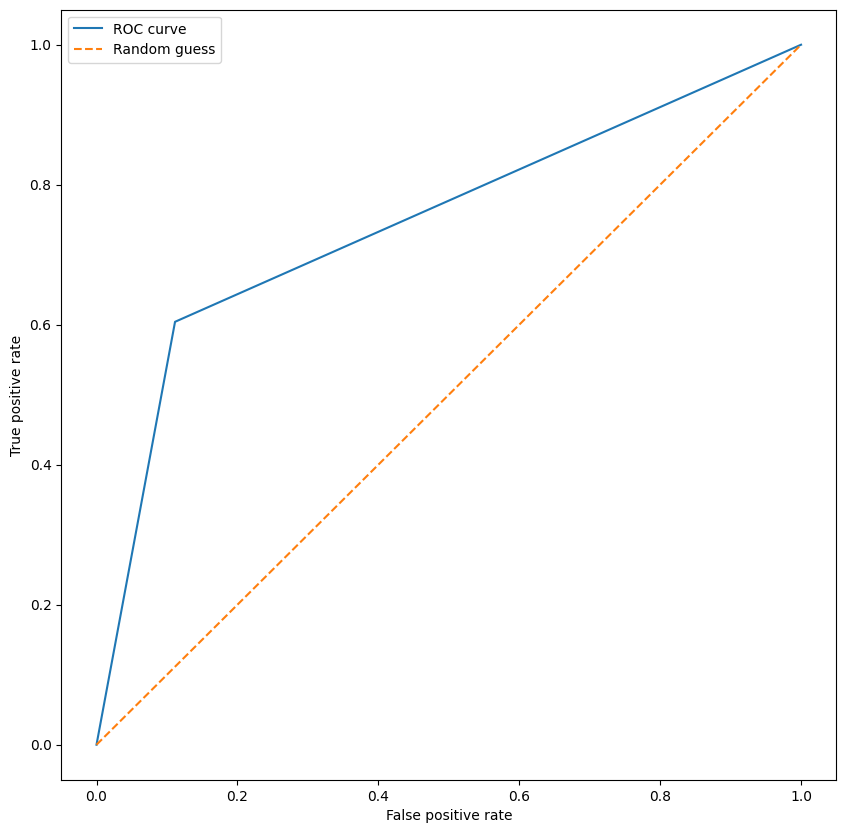

In [48]:
plt.figure(figsize=(10,10))
plt.plot(fpr, tpr, label="ROC curve")
plt.plot([0,1], [0,1], linestyle="--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.show()